## Prepare python environment


In [76]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

%matplotlib inline

In [77]:
random_state=5 # use this to control randomness across runs e.g., dataset partitioning

## Preparing the Glass Dataset (2 points)

---


We will use glass dataset from UCI machine learning repository. Details for this data can be found [here](https://archive.ics.uci.edu/dataset/42/glass+identification).
The objective of the dataset is to identify the class of glass based on the following features:

1. RI: refractive index
2. Na: Sodium
3. Mg: Magnesium
4. Al: Aluminum
5. Si: Silica
6. K: Potassium
7. Ca: Calcium
8. Ba: Barium
9. Fe: Iron
10. Type of glass (Target label)

The classes of glass are:

1. building_windows_float_processed
2. building_windows_non_float_processed
3. vehicle_windows_float_processed
4. containers
5. tableware
6. headlamps

Identification of glass from its content can be used for forensic analysis.

### Loading the dataset

In [78]:
# Download and load the dataset
import os
if not os.path.exists('glass.csv'):
    !wget https://raw.githubusercontent.com/JHA-Lab/ece364_2026/master/data/glass.csv
data = pd.read_csv('glass.csv')

# Display the first five instances in the dataset
data.head(5)

,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe,Type
0,1.52101,13.64,4.49,1.10,71.78,0.06,8.75,0.0,0.0,1
1,1.51761,13.89,3.60,1.36,72.73,0.48,7.83,0.0,0.0,1
2,1.51618,13.53,3.55,1.54,72.99,0.39,7.78,0.0,0.0,1
3,1.51766,13.21,3.69,1.29,72.61,0.57,8.22,0.0,0.0,1
4,1.51742,13.27,3.62,1.24,73.08,0.55,8.07,0.0,0.0,1


# Adding Additional Features

1. Ca_Na: Calcium Sodium
2. Al_Mg: Aluminum Magnesium
3. Ca_Mg: Calcium Magnesium

In [79]:
# Additional features to be added to the data
data['Ca_Na'] = data.Ca*data.Na
data['Al_Mg'] = data.Al*data.Mg
data['Ca_Mg'] = data.Ca*data.Mg

# get column names
col_names = data.columns

### Check the data type for each column

In [80]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 214 entries, 0 to 213
Data columns (total 13 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   RI      214 non-null    float64
 1   Na      214 non-null    float64
 2   Mg      214 non-null    float64
 3   Al      214 non-null    float64
 4   Si      214 non-null    float64
 5   K       214 non-null    float64
 6   Ca      214 non-null    float64
 7   Ba      214 non-null    float64
 8   Fe      214 non-null    float64
 9   Type    214 non-null    int64  
 10  Ca_Na   214 non-null    float64
 11  Al_Mg   214 non-null    float64
 12  Ca_Mg   214 non-null    float64
dtypes: float64(12), int64(1)
memory usage: 21.9 KB


#### Look at some statistics of the data using the `describe` function in pandas.

In [81]:
data.describe()

,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe,Type,Ca_Na,Al_Mg,Ca_Mg
count,214.000000,214.000000,214.000000,214.000000,214.000000,214.000000,214.000000,214.000000,214.000000,214.000000,214.000000,214.000000,214.000000
mean,1.518365,13.407850,2.684533,1.444907,72.650935,0.497056,8.956963,0.175047,0.057009,2.780374,119.775005,3.533553,23.138600
std,0.003037,0.816604,1.442408,0.499270,0.774546,0.652192,1.423153,0.497219,0.097439,2.103739,17.796541,2.075049,12.465510
min,1.511150,10.730000,0.000000,0.290000,69.810000,0.000000,5.430000,0.000000,0.000000,1.000000,74.336700,0.000000,0.000000
25%,1.516522,12.907500,2.115000,1.190000,72.280000,0.122500,8.240000,0.000000,0.000000,1.000000,108.515575,2.378700,19.124100
50%,1.517680,13.300000,3.480000,1.360000,72.790000,0.555000,8.600000,0.000000,0.000000,2.000000,113.256650,4.149700,28.835250
75%,1.519157,13.825000,3.600000,1.630000,73.087500,0.610000,9.172500,0.000000,0.100000,3.000000,129.368700,4.922325,30.687825
max,1.533930,17.380000,4.490000,3.500000,75.410000,6.210000,16.190000,3.150000,0.510000,7.000000,199.137000,9.380000,39.287500


1. Count tells us the number of Non-empty rows in a feature.

2. Mean tells us the mean value of that feature.

3. Std tells us the Standard Deviation Value of that feature.

4. Min tells us the minimum value of that feature.

5. 25%, 50%, and 75% are the percentile/quartile of each feature.

6. Max tells us the maximum value of that feature.

### Visualize the Data

#### Check how many instances of each target class are there in the data. This has been done for you.

Text(0, 0.5, 'Count')

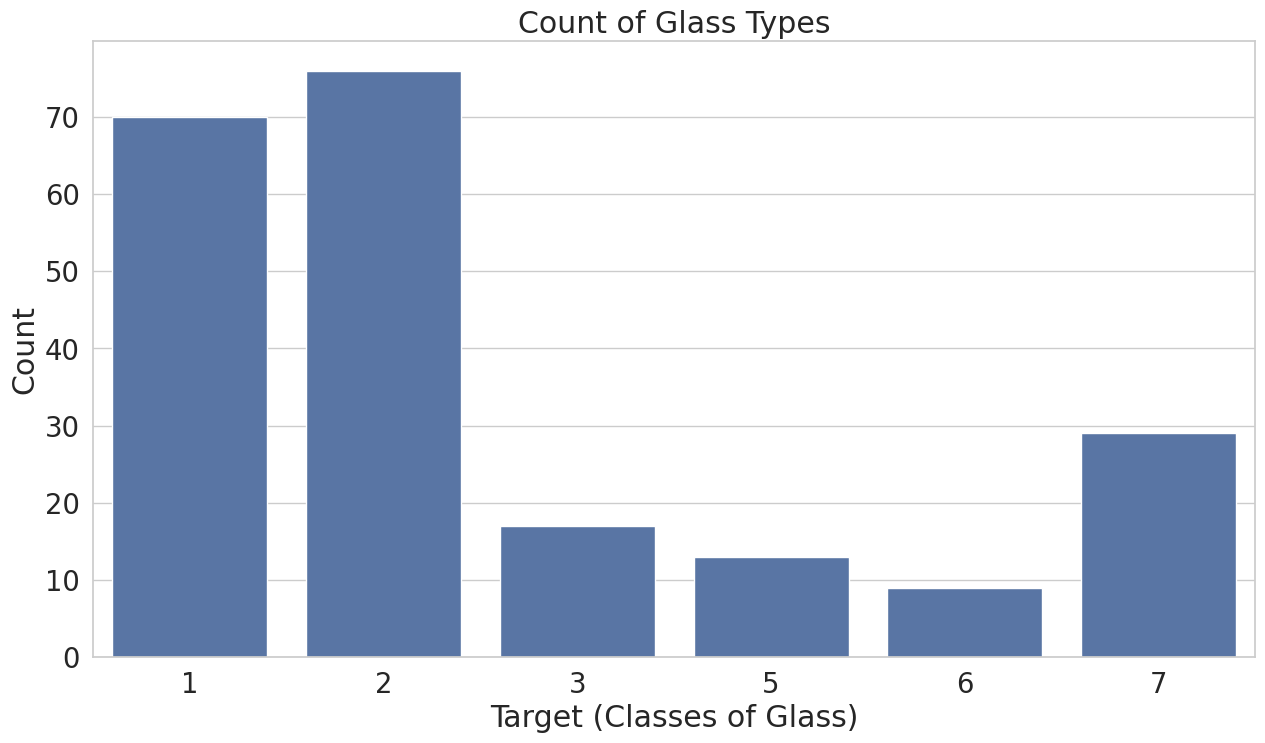

In [82]:
sns.set_theme(style="whitegrid", font_scale=1.8)
plt.subplots(figsize = (15,8))
sns.countplot(x='Type',data=data).set_title('Count of Glass Types')
plt.xlabel('Target (Classes of Glass)')
plt.ylabel('Count')

#### Calculate `mean` values for each feature grouped by target. This has been done for you.

In [83]:
# Compute mean values for each feature grouped by target
data.groupby('Type', as_index=False).mean()

,Type,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe,Ca_Na,Al_Mg,Ca_Mg
0,1,1.518718,13.242286,3.552429,1.163857,72.619143,0.447429,8.797286,0.012714,0.057000,116.590990,4.108247,31.271384
1,2,1.518619,13.111711,3.002105,1.408158,72.598026,0.521053,9.073684,0.050263,0.079737,118.402543,4.333504,25.144126
2,3,1.517964,13.437059,3.543529,1.201176,72.404706,0.406471,8.782941,0.008824,0.057059,118.137300,4.217241,31.159494
3,5,1.518928,12.827692,0.773846,2.033846,72.366154,1.470000,10.123846,0.187692,0.060769,129.290469,1.724108,7.311938
4,6,1.517456,14.646667,1.305556,1.366667,73.206667,0.000000,9.356667,0.000000,0.000000,136.140600,1.988589,12.059867
5,7,1.517116,14.442069,0.538276,2.122759,72.965862,0.325172,8.491379,1.040000,0.013448,122.672859,0.939755,4.082914


#### Create box plots to see distribution of each feature. See [here](https://seaborn.pydata.org/generated/seaborn.boxplot.html) for further details. This has been done for you.

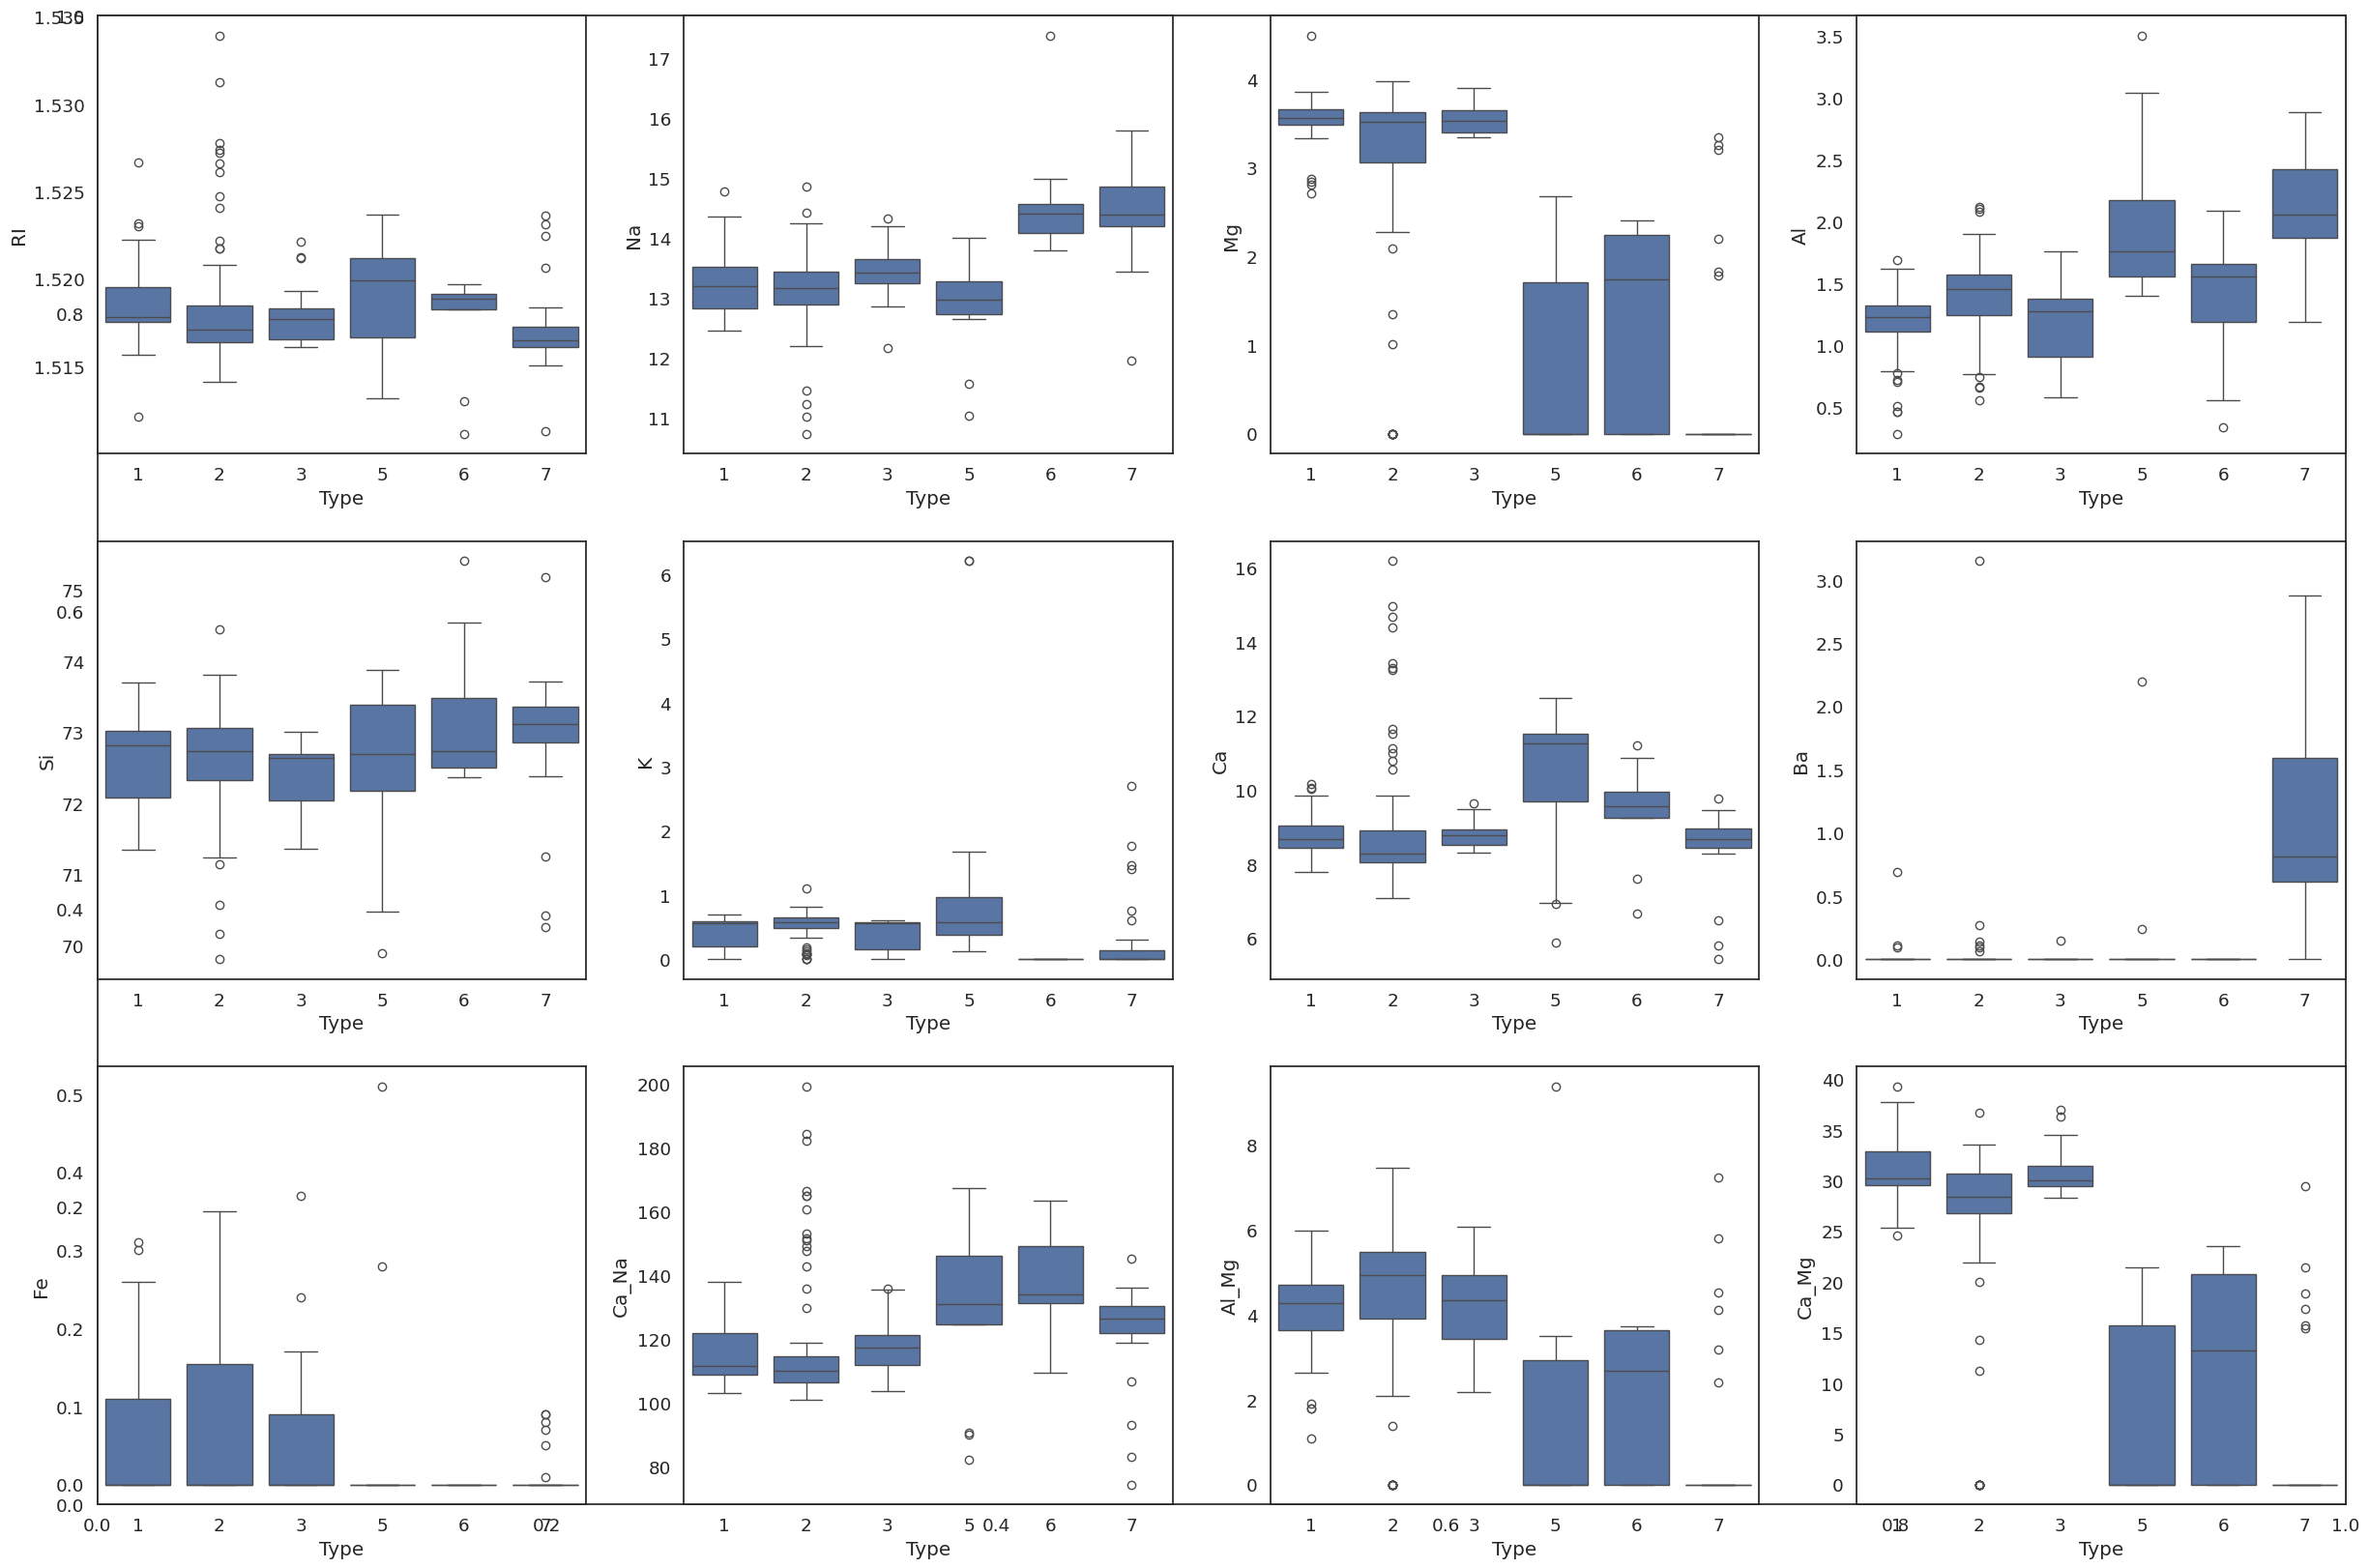

In [84]:
sns.set_theme(style="white", font_scale=1.2)
plt.subplots(figsize = (30,20))
plt.subplot(3,4,1)
sns.boxplot(x='Type', y='RI', data=data)
plt.subplot(3,4,2)
sns.boxplot(x='Type', y='Na', data=data)
plt.subplot(3,4,3)
sns.boxplot(x='Type', y='Mg', data=data)
plt.subplot(3,4,4)
sns.boxplot(x='Type', y='Al', data=data)
plt.subplot(3,4,5)
sns.boxplot(x='Type', y='Si', data=data)
plt.subplot(3,4,6)
sns.boxplot(x='Type', y='K', data=data)
plt.subplot(3,4,7)
sns.boxplot(x='Type', y='Ca', data=data)
plt.subplot(3,4,8)
sns.boxplot(x='Type', y='Ba', data=data)
plt.subplot(3,4,9)
sns.boxplot(x='Type', y='Fe', data=data)
plt.subplot(3,4,10)
sns.boxplot(x='Type', y='Ca_Na', data=data)
plt.subplot(3,4,11)
sns.boxplot(x='Type', y='Al_Mg', data=data)
plt.subplot(3,4,12)
sns.boxplot(x='Type', y='Ca_Mg', data=data)
plt.show()

#### Create a pairplot to display pairwise relationship. See [here](https://seaborn.pydata.org/generated/seaborn.pairplot.html) for further details. This has been done for you.

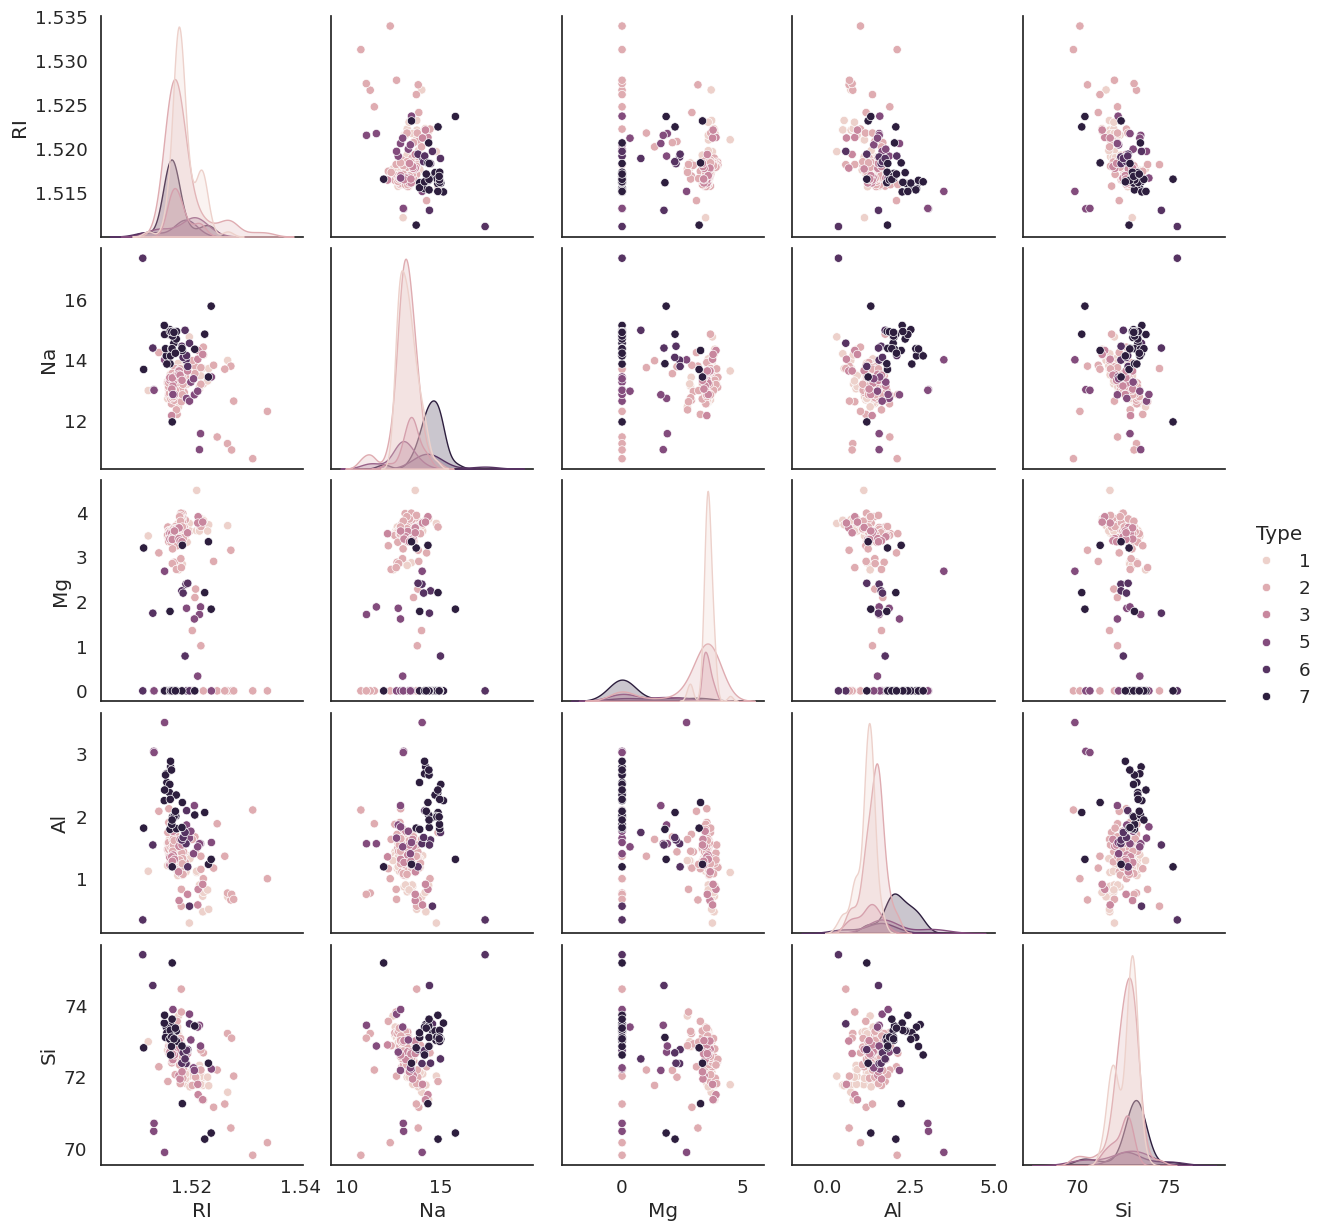

In [85]:
from IPython.display import display, HTML
display(HTML("<style>.container { width:100% !important; }</style>"))
# Select a subset of features for visualization
sns.pairplot(data[['RI','Na','Mg','Al','Si','Type']], hue='Type')

<Axes: >

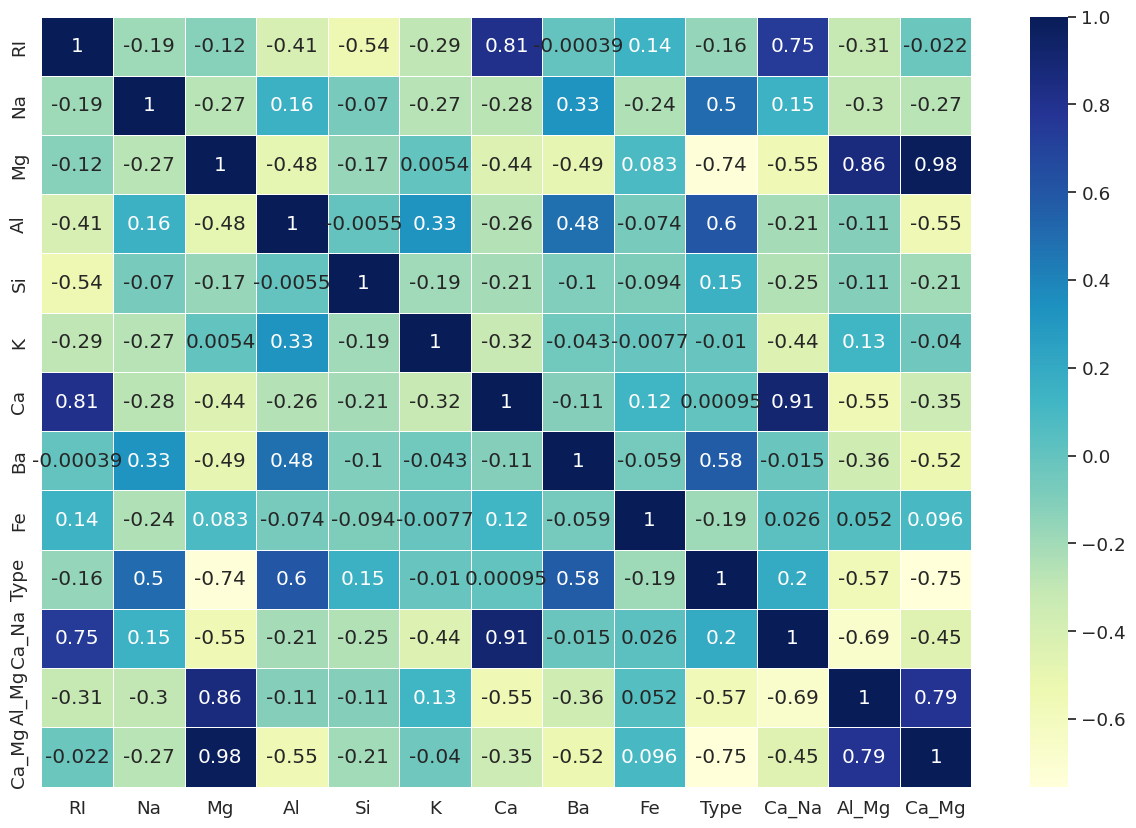

In [86]:
# Plot heatmap showing correlation between different features
plt.subplots(figsize=(15,10))
sns.heatmap(data.corr(),cmap='YlGnBu',annot=True, linewidth=.5)

### Extract target and descriptive features (1 point)

#### Separate the target and features from the data.

---



In [87]:
# Store all the features from the data in X
X = data.drop(columns='Type')

# Store all the labels in y
y = data['Type']

In [88]:
# Convert data to numpy array
X = X.to_numpy()
y = y.to_numpy()

### Create training and validation datasets (1 point)


We will split the dataset into training and validation set. Generally in machine learning, we split the data into training,
validation and test set (this will be covered in later chapters). The model with best performance on the validation set is used to evaluate perfromance on
the test set which is the unseen data. In this assignment, we will using `train set` for training and evaluate the performance on the `validation set` for various
model configurations to determine the best hyperparameters (parameter setting yielding the best performance).

Split the data into training and validation set using `train_test_split`.  See [here](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html) for details. To get consistent result while splitting, set `random_state` to the value defined earlier. We use 80% of the data for training and 20% of the data for validation. This has been done for you.

In [89]:
X_train,X_val,y_train,y_val = train_test_split(X,y,test_size=.2,random_state=random_state) # 80% training and 20% validation

## Training Decision Tree-based Classifiers (18 points)


### Exercise 1: Learning a Decision Tree (10 points)

#### We will use the `sklearn` library to train a Decision Tree classifier. Review ch.4 and see [here](https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html) for more details.

In [90]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

In [91]:
# tree visualization helper function
from sklearn.tree import export_graphviz
from six import StringIO
from IPython.display import Image
import pydotplus

"""
clf: DecisionTreeClassifier

Returns a bytes object representing the image of the tree
"""
def get_tree_image(clf):
    dot_data = StringIO()
    feature_names=data.drop('Type',axis=1).columns
    class_names=["Building_windows_float_processed", "Building_windows_non_float_processed", "Vehicle_windows_float_processed", "Containers", "Tableware", "Headlamps"]
    export_graphviz(clf, out_file=dot_data,
                    filled=True, rounded=True,
                    special_characters=True,
                    feature_names=feature_names,
                    class_names=class_names)
    graph = pydotplus.graph_from_dot_data(dot_data.getvalue())


    return graph.create_png()

#### Exercise 1a: Fit and interpret a decision tree. (6 points)

#### Fit Decision trees using the Gini index and entropy-based impurity measure.

#### Set the random_state to the value defined above. Keep all other parameters at their default values.

#### Report the training and validation set accuracies for each classifier.

In [92]:
# Create decision tree classifiers using both criteria

#### Visualize the Decision Tree with the best validation performance.

Training Set Accuracy Score:
1.0
Validation Set Accuracy Score:
0.7674418604651163


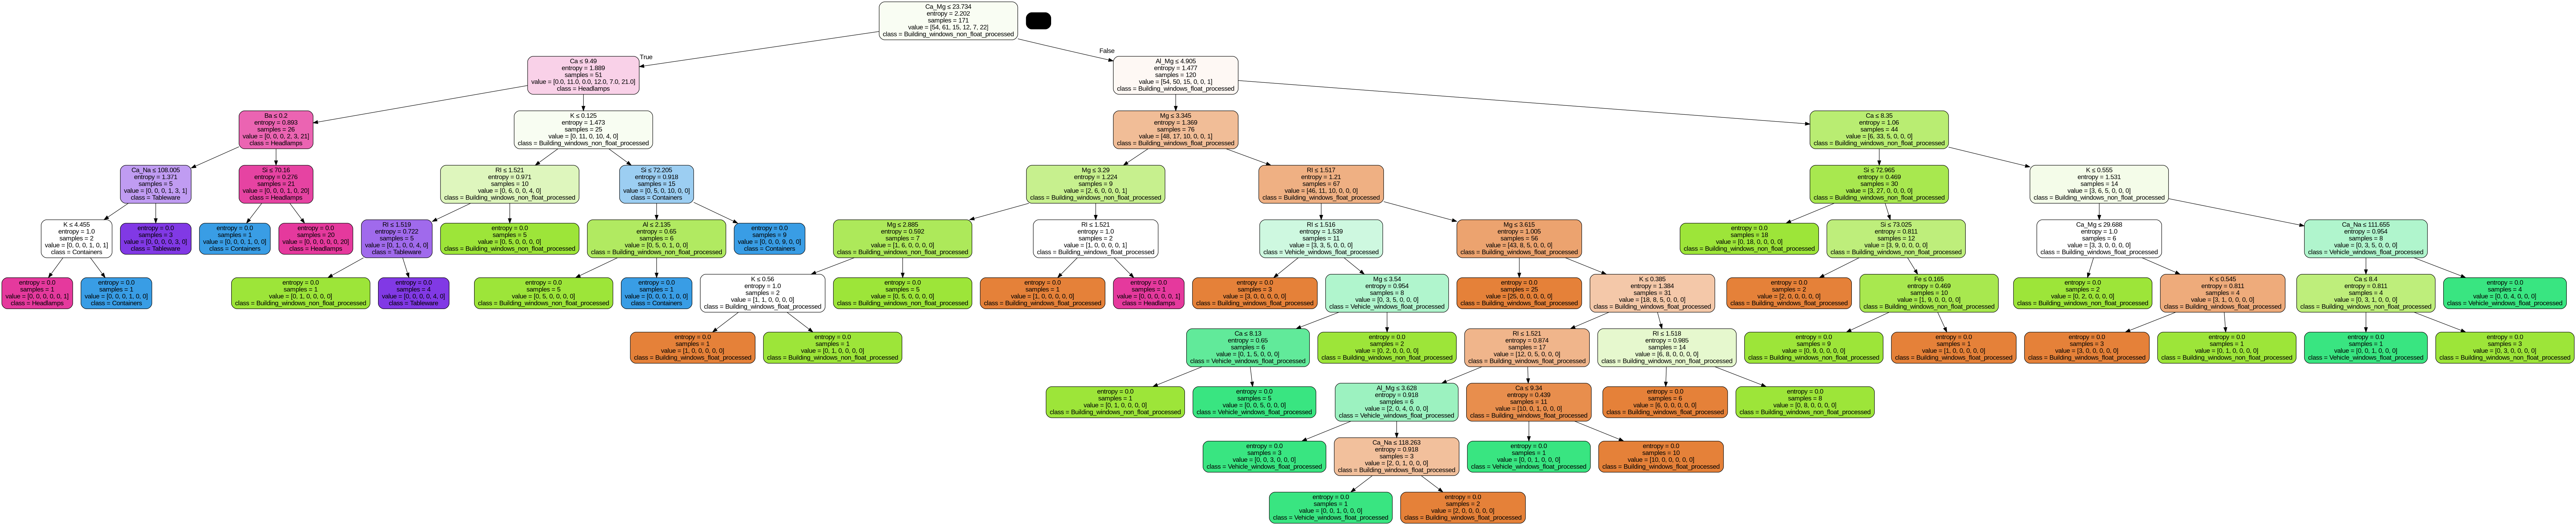

In [93]:
entropy_clf = DecisionTreeClassifier(criterion='entropy', random_state = random_state)
entropy_clf.fit(X_train, y_train)
best_clf=entropy_clf
print("Training Set Accuracy Score:")
print(accuracy_score(entropy_clf.predict(X = X_train), y_train))
print("Validation Set Accuracy Score:")
print(accuracy_score(entropy_clf.predict(X = X_val), y_val))
tree_image=get_tree_image(best_clf)
Image(tree_image)

Training Set Accuracy Score:
1.0
Validation Set Accuracy Score:
0.7209302325581395


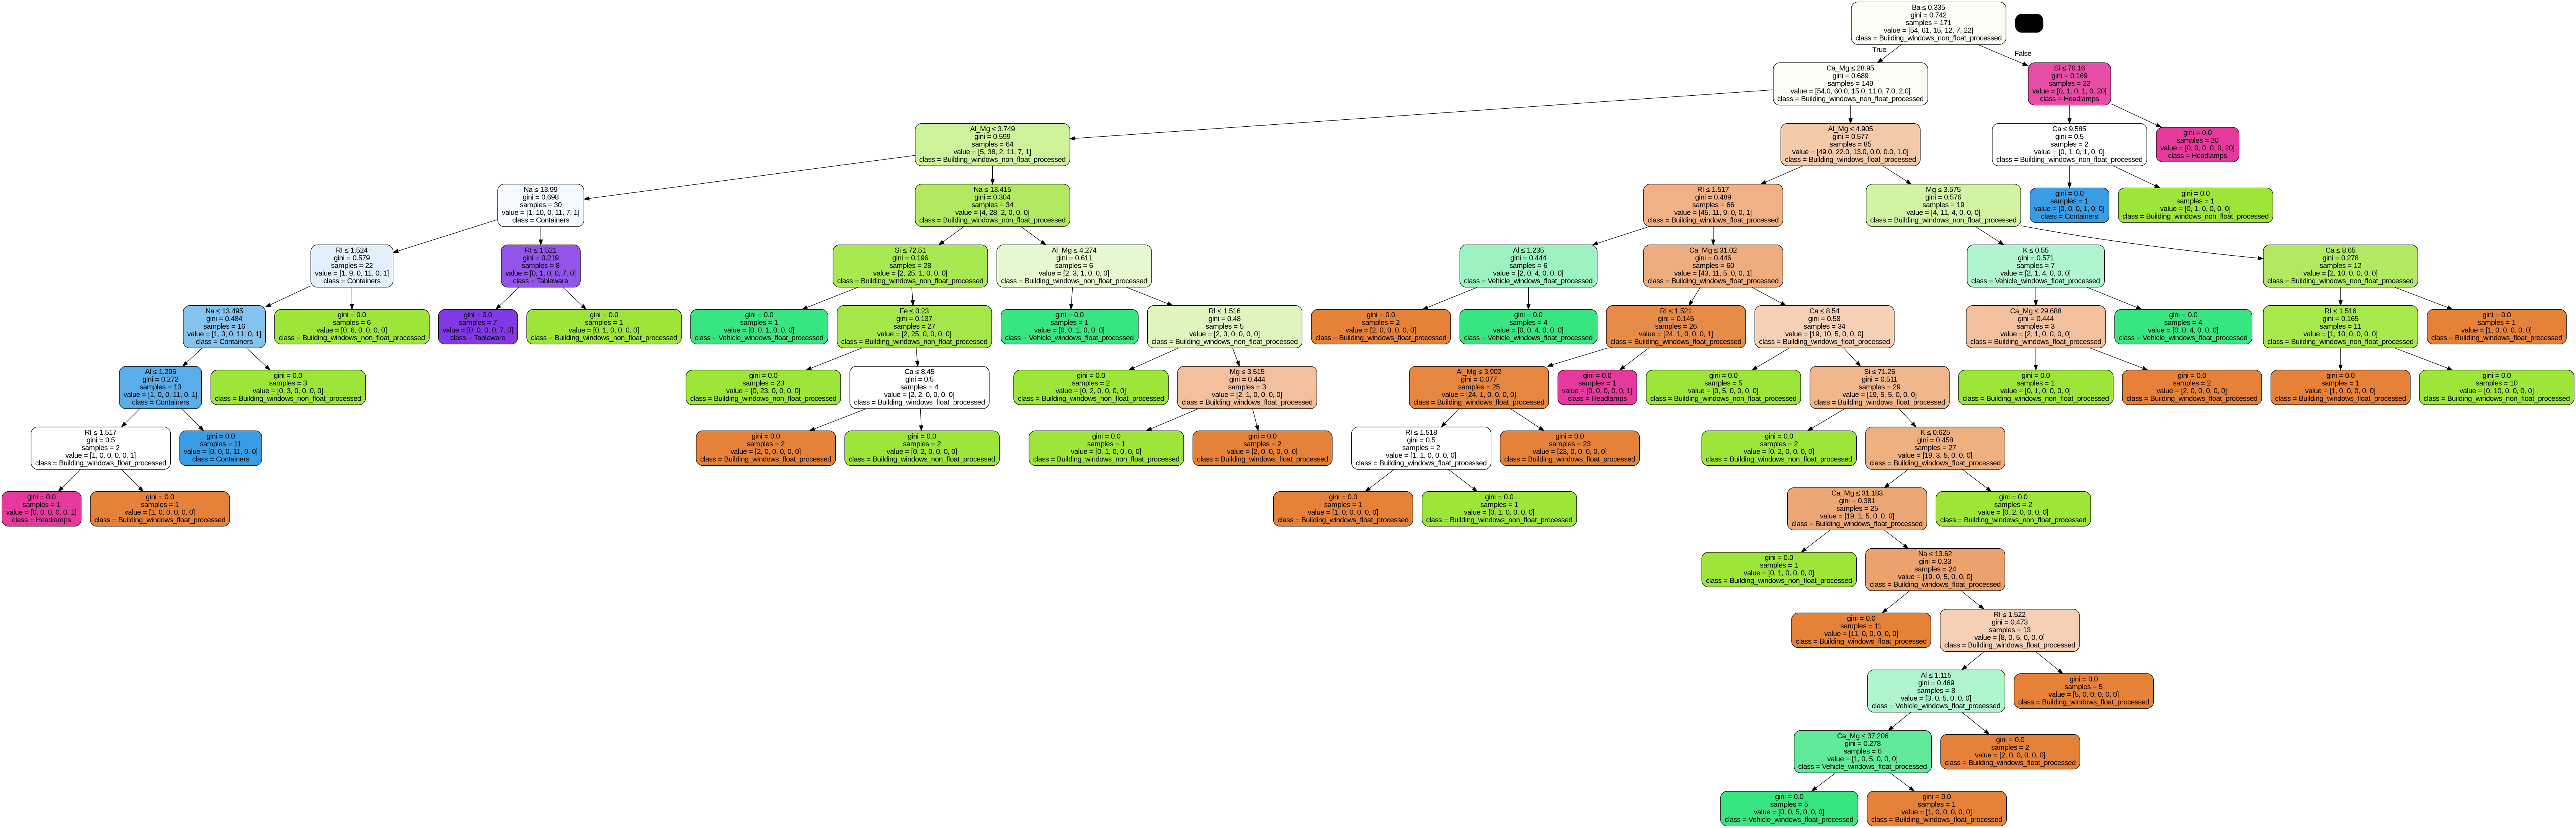

In [94]:
gini_clf = DecisionTreeClassifier(criterion='gini', random_state = random_state)
gini_clf.fit(X_train, y_train)
best_clf=gini_clf
print("Training Set Accuracy Score:")
print(accuracy_score(gini_clf.predict(X = X_train), y_train))
print("Validation Set Accuracy Score:")
print(accuracy_score(gini_clf.predict(X = X_val), y_val))
tree_image=get_tree_image(best_clf)
Image(tree_image)

#### Indicate the most informative descriptive feature (with the threshold) and briefly explain why this is the most informative (from an algorithmic viewpoint).

**Answer:**
Entropy: Ca_Mg (an interaction term between Calcium and Magnesium) =< 23.734 is the most informative feature, as shown by the fact that it is the top of the decision tree. The algorithm selects this split because it produces the greatest information gain among the candidate feature threshold combinations. This means that it gives teh largest reduction in ewntropy from the parent node to teh weighted average entropy of its two children, making it the most informative initial split for this training dataset.

Gini: Barium =< 0.335 is the most informative feature for the same reason as the entropy model's most informative feature, just with the Gini Index being used to determine information gain instead of entropy.

#### Briefly comment on the tree's depth and what factors may contribute to the shallowness/complexity of the tree.


**Answer:** The trees are 10-14 levels deep and very complex. This is largely because the model is trying to explain every instance and there are many factors that it can use to do so. Because the variables are continuous, it can define many thresholds to create thresholds that result in a decision tree that is consistent with the data. It also has 12 descriptive features to do so with, making it even easier. If there are no two points that have the exact same calibrations (which is highly unlikely given these facts), then the model can make many subtrees to explain every change in glass type. Consequently, right now, both models are completely consistent (and thus likely overfitted) with the data, as shown by the fact that the training accuracies are both 1.0 - a perfect fit.  

#### Show how one can interpret the tree by specifying the rule from its left most branch.

**Answer:** Every arrow to the left means that the instrance being sorted is true according to the node. Every arrow to the right means it is false.

The following are the sorting steps to get to the leftmost branch. The instance:
1. has a Ba value =< 0.335 (so, move down and left)
2. has a Ca_Mg value =< 28.95 (so, move down and left)
3. has an Al_Mg value =< 3.749 (so, move down and left)
4. has an Na value =< 13.99 (so, move down and left)
5. has an RI value =< 1.524 (so, move down and left)
6. has an Na value =< 13.495 (so, move down and left)
7. has an Al value =< 1.295 (so, move down and left)
8. has an RI value =< 1.517 (so, move down and left)
9. Type == headlamps [tree terminates with this assignment of type]

#### Exercise 1b: Preprune a decision tree. (2 points)

#### Next, let's try pruning the tree to see if we can improve the classifier's generalization performance.

#### Preprune a decision tree by varying the `max_depth` among {None (no depth control), 1,3,5,7}.

#### Set the criterion to entropy and the random_state to the value defined above. Keep all other parameters at their default values.

#### Report the training and validation set accuracies for each classifier.

In [100]:
print("Entropy")

entropy_clf = DecisionTreeClassifier(criterion='entropy', random_state = random_state)
entropy_clf.fit(X_train, y_train)
best_clf=entropy_clf
print("Training Set Accuracy (Max Depth==None):")
print(accuracy_score(entropy_clf.predict(X = X_train), y_train))
print("Validation Set Accuracy (Max Depth==None):")
print(accuracy_score(entropy_clf.predict(X = X_val), y_val))
# tree_image=get_tree_image(best_clf)
# Image(tree_image)

entropy_clf = DecisionTreeClassifier(criterion='entropy', max_depth = 1, random_state = random_state)
entropy_clf.fit(X_train, y_train)
best_clf=entropy_clf
print("Training Set Accuracy (Max Depth==1):")
print(accuracy_score(entropy_clf.predict(X = X_train), y_train))
print("Validation Set Accuracy (Max Depth==1):")
print(accuracy_score(entropy_clf.predict(X = X_val), y_val))
# tree_image=get_tree_image(best_clf)
# Image(tree_image)

entropy_clf = DecisionTreeClassifier(criterion='entropy', max_depth = 3, random_state = random_state)
entropy_clf.fit(X_train, y_train)
best_clf=entropy_clf
print("Training Set Accuracy (Max Depth==3):")
print(accuracy_score(entropy_clf.predict(X = X_train), y_train))
print("Validation Set Accuracy (Max Depth==3):")
print(accuracy_score(entropy_clf.predict(X = X_val), y_val))
# tree_image=get_tree_image(best_clf)
# Image(tree_image)

entropy_clf = DecisionTreeClassifier(criterion='entropy', max_depth = 5, random_state = random_state)
entropy_clf.fit(X_train, y_train)
best_clf=entropy_clf
print("Training Set Accuracy (Max Depth==5):")
print(accuracy_score(entropy_clf.predict(X = X_train), y_train))
print("Validation Set Accuracy (Max Depth==5):")
print(accuracy_score(entropy_clf.predict(X = X_val), y_val))
# tree_image=get_tree_image(best_clf)
# Image(tree_image)

entropy_clf = DecisionTreeClassifier(criterion='entropy', max_depth = 7, random_state = random_state)
entropy_clf.fit(X_train, y_train)
best_clf=entropy_clf
print("Training Set Accuracy (Max Depth==7):")
print(accuracy_score(entropy_clf.predict(X = X_train), y_train))
print("Validation Set Accuracy (Max Depth==7):")
print(accuracy_score(entropy_clf.predict(X = X_val), y_val))
# tree_image=get_tree_image(best_clf)
# Image(tree_image)

print("Gini Index")

gini_clf = DecisionTreeClassifier(criterion='gini', random_state = random_state)
gini_clf.fit(X_train, y_train)
best_clf=gini_clf
print("Training Set Accuracy (Max Depth==None):")
print(accuracy_score(gini_clf.predict(X = X_train), y_train))
print("Validation Set Accuracy (Max Depth==None):")
print(accuracy_score(gini_clf.predict(X = X_val), y_val))
# tree_image=get_tree_image(best_clf)
# Image(tree_image)

gini_clf = DecisionTreeClassifier(criterion='gini', max_depth = 1, random_state = random_state)
gini_clf.fit(X_train, y_train)
best_clf=gini_clf
print("Training Set Accuracy (Max Depth==1):")
print(accuracy_score(gini_clf.predict(X = X_train), y_train))
print("Validation Set Accuracy (Max Depth==1):")
print(accuracy_score(gini_clf.predict(X = X_val), y_val))
# tree_image=get_tree_image(best_clf)
# Image(tree_image)

gini_clf = DecisionTreeClassifier(criterion='gini', max_depth = 3, random_state = random_state)
gini_clf.fit(X_train, y_train)
best_clf=gini_clf
print("Training Set Accuracy (Max Depth==3):")
print(accuracy_score(gini_clf.predict(X = X_train), y_train))
print("Validation Set Accuracy (Max Depth==3):")
print(accuracy_score(gini_clf.predict(X = X_val), y_val))
# tree_image=get_tree_image(best_clf)
# Image(tree_image)

gini_clf = DecisionTreeClassifier(criterion='gini', max_depth = 5, random_state = random_state)
gini_clf.fit(X_train, y_train)
best_clf=gini_clf
print("Training Set Accuracy (Max Depth==5):")
print(accuracy_score(gini_clf.predict(X = X_train), y_train))
print("Validation Set Accuracy (Max Depth==5):")
print(accuracy_score(gini_clf.predict(X = X_val), y_val))
# tree_image=get_tree_image(best_clf)
# Image(tree_image)

gini_clf = DecisionTreeClassifier(criterion='gini', max_depth = 7, random_state = random_state)
gini_clf.fit(X_train, y_train)
best_clf=gini_clf
print("Training Set Accuracy (Max Depth==7):")
print(accuracy_score(gini_clf.predict(X = X_train), y_train))
print("Validation Set Accuracy (Max Depth==7):")
print(accuracy_score(gini_clf.predict(X = X_val), y_val))
# tree_image=get_tree_image(best_clf)
# Image(tree_image)

Entropy
Training Set Accuracy (Max Depth==None):
1.0
Validation Set Accuracy (Max Depth==None):
0.7674418604651163
Training Set Accuracy (Max Depth==1):
0.43859649122807015
Validation Set Accuracy (Max Depth==1):
0.5348837209302325
Training Set Accuracy (Max Depth==3):
0.7251461988304093
Validation Set Accuracy (Max Depth==3):
0.6511627906976745
Training Set Accuracy (Max Depth==5):
0.8830409356725146
Validation Set Accuracy (Max Depth==5):
0.7441860465116279
Training Set Accuracy (Max Depth==7):
0.9824561403508771
Validation Set Accuracy (Max Depth==7):
0.7906976744186046
Gini Index
Training Set Accuracy (Max Depth==None):
1.0
Validation Set Accuracy (Max Depth==None):
0.7209302325581395
Training Set Accuracy (Max Depth==1):
0.4678362573099415
Validation Set Accuracy (Max Depth==1):
0.4883720930232558
Training Set Accuracy (Max Depth==3):
0.6842105263157895
Validation Set Accuracy (Max Depth==3):
0.627906976744186
Training Set Accuracy (Max Depth==5):
0.8362573099415205
Validation Set

#### Analyze the effect of increasing tree depth on training and validation performance.



**Answer:**

Training Performance: As the tree depth increased, the training accuracy increased. This always held true. There were relatively significant jumps at each level increase, but the largest jump was from 1 to 3. That is because it is being allowed to fit more and more to the training data as it is allowed to add new levels.

Validation Performance: As the tree depth increased iteratively from 1 to 7, the accuracy increased. However, that principle did not hold when the tree depth was allowed to grow to 10-14, as it was when it was not given a limit depth. The validation set accuracy was the greatest at level 7 (although for the entropy model levels 5 and 7 had the same validation accuracy. For both models, the largest jump in accuracy by far was between level 1 and 3.

#### Exercise 1c: Postprune a decision tree. (2 points)

#### Implement reduced error pruning on the two decision trees that you previously trained in Exercise 1a. Use the validation set to decide which nodes to prune.

#### Report the validation set accuracies for each classifier after pruning.

#### The pruning function is partly writen, please fill in the TODO part. Review ch.4.4.4 for more details.


In [96]:
# Fit new trees if you want to keep the trees in 1a unmodified
gini_clf = DecisionTreeClassifier(criterion='gini', random_state = random_state)
gini_clf.fit(X_train, y_train)
entropy_clf = DecisionTreeClassifier(criterion='entropy', random_state = random_state)
entropy_clf.fit(X_train, y_train)

def reduced_error_pruning(dtree, X_val, y_val):
    """
    Perform reduced error pruning on a decision tree classifier.

    This function directly modifies the decision tree passed as an argument.

    Args:
    dtree: DecisionTreeClassifier
        The decision tree to prune, must be already fitted.
    X_val: array-like
        Validation features used to prune the tree.
    y_val: array-like
        Validation labels used to determine pruning effectiveness.

    Returns:
    dtree: DecisionTreeClassifier
        The pruned decision tree.
    """

    # Access the internal tree structure to identify non-leaf nodes
    non_leaf_nodes = [i for i in range(dtree.tree_.node_count) if dtree.tree_.children_left[i] != dtree.tree_.children_right[i]]

    # Track the best accuracy and corresponding tree configuration. initialize with original accuracy.
    best_acc = accuracy_score(dtree.predict(X = X_val), y_val)

    # Iterate over non-leaf nodes in reverse order to consider pruning from the bottom up
    for i in reversed(non_leaf_nodes):
        # Store current node children to restore if needed
        left, right = dtree.tree_.children_left[i], dtree.tree_.children_right[i]

        # Temporarily make the node a leaf
        dtree.tree_.children_left[i], dtree.tree_.children_right[i] = -1, -1

        # Calculate the accuracy of the tree with the node pruned (turned into a leaf)
        temp_acc = accuracy_score(dtree.predict(X = X_val), y_val)

        if temp_acc < best_acc: # Revert pruning if accuracy decreases
            # Restore the node to its original state
            dtree.tree_.children_left[i], dtree.tree_.children_right[i] = left, right
        else:
            # Update the best accuracy observed
            best_acc = accuracy_score(dtree.predict(X = X_val), y_val)

    return dtree  # Return the modified tree


pruned_entropy = reduced_error_pruning(entropy_clf, X_val, y_val)
pruned_entropy_acc = accuracy_score(pruned_entropy.predict(X = X_val), y_val)
print(f"Validation accuracy of entropy tree after pruning: {pruned_entropy_acc:.4f}")

pruned_gini = reduced_error_pruning(gini_clf, X_val, y_val)
pruned_gini_acc = accuracy_score(pruned_gini.predict(X = X_val), y_val)
print(f"Validation accuracy of gini tree after pruning: {pruned_gini_acc:.4f}")

Validation accuracy of entropy tree after pruning: 0.8372
Validation accuracy of gini tree after pruning: 0.7907


### Exercise 2: Learning an Ensemble of Decision Trees (8 points)

#### We will use the `sklearn` library to implement bagging and boosting. Review ch.4 and read more on [bagging](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html) and [boosting](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.GradientBoostingClassifier.html).

In [97]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier

#### Exercise 2a: Fit a Random Forest. (4 points)

#### Fit different Random Forest classifiers by varying the number of trees among {10, 50, 100, 400, 1000}.

#### Set the `criterion` to entropy and set the random_state to the value defined above. Keep all other parameters at their default values.

#### Report the validation set accuracies for each classifier.

In [98]:
random_forest_10 = RandomForestClassifier(n_estimators=10, criterion = 'entropy', random_state = random_state)
random_forest_10.fit(X_train, y_train)
random_forest_50 = RandomForestClassifier(n_estimators=50, criterion = 'entropy', random_state = random_state)
random_forest_50.fit(X_train, y_train)
random_forest_100 = RandomForestClassifier(n_estimators=100, criterion = 'entropy', random_state = random_state)
random_forest_100.fit(X_train, y_train)
random_forest_400 = RandomForestClassifier(n_estimators=400, criterion = 'entropy', random_state = random_state)
random_forest_400.fit(X_train, y_train)
random_forest_1000 = RandomForestClassifier(n_estimators=1000, criterion = 'entropy', random_state = random_state)
random_forest_1000.fit(X_train, y_train)

random_forest_10_accuracy = random_forest_10.score(X_val, y_val)
random_forest_50_accuracy = random_forest_50.score(X_val, y_val)
random_forest_100_accuracy = random_forest_100.score(X_val, y_val)
random_forest_400_accuracy = random_forest_400.score(X_val, y_val)
random_forest_1000_accuracy = random_forest_1000.score(X_val, y_val)

print("Validation Set Accuracies for Random Forest, Number of Trees Varying")
print(f"10 Trees: {random_forest_10_accuracy:.6f}")
print(f"50 Trees: {random_forest_50_accuracy:.6f}")
print(f"100 Trees: {random_forest_100_accuracy:.6f}")
print(f"400 Trees: {random_forest_400_accuracy:.6f}")
print(f"1000 Trees: {random_forest_1000_accuracy:.6f}")

Validation Set Accuracies for Random Forest, Number of Trees Varying
10 Trees: 0.744186
50 Trees: 0.813953
100 Trees: 0.790698
400 Trees: 0.837209
1000 Trees: 0.837209


#### Comment on the effect of increasing the number of trees on validation performance. Compare the performance of the best performing Random Forest classifier against the Decision Tree Classifier trained with entropy (Ex. 1a) and explain any difference.

**Answer:** Increasing the number of trees increases the validation performance. This is not linear, however. The initial increase from 10=>50 is the greates jump. The increase from 50=>100 is similarly significant, but then there is no change as it jumps from 100 to 400 to 1000. There are therefore diminishing returns as the number of trees increases.

If you mean the basic entropy decision tree classifier in 1a, which reached a validation accuracy of 0.767441860465116, is less accurate than the Random Forest highest accury, which was 0.8372 with 100, 400, and 1000 trees. This is likely because the initial decision tree model was overfitted (1b suggests this because of the validation accuracy increased when I restricted the depth of the model).  

If you mean all of 1, the best performing Decision Tree Classifier (both the entropy and gini index trees after reduced error post-pruning) got a validation test accuracy of 0.8372. This is the same as the highest validation test accuracy of 0.8372 with 100, 400, and 1000 trees in a Random Forest.  This difference means that a Random Forest model is similarly suited to predict the target feature for this data. If there was a difference, which there is not, it could be because there was some type of internalized error in the assumptions/conclusions of the previous tree. Maybe the data was falsely understanding a certain threshold to be the most important based off of its training data. Using Random Trees, which combine a number of decision trees based on different subsections of instances and descriptive features, this false conclusion was likely only concluded in a subsection of the trees in the Random Forest, and therefore was moderated out in the process of aggregating the models.

#### Exercise 2b: Fit a Gradient Boosted Decision Tree (GBDT). (4 points)

#### Fit different GBDTs by varying the number of boosting steps/trees added among {5, 10, 20, 50, 100, 200}.

#### Set the `n_iter_no_change` to 100, `validation_fraction=0.2`, and random_state to the value defined above. Keep all other parameters at their default values.

#### Report the training and validation set accuracies for each classifier.

In [99]:
GBDT_5 = GradientBoostingClassifier(n_estimators = 5, n_iter_no_change = 100, validation_fraction=0.2, random_state = random_state)
GBDT_10 = GradientBoostingClassifier(n_estimators = 10, n_iter_no_change = 100, validation_fraction=0.2, random_state = random_state)
GBDT_20 = GradientBoostingClassifier(n_estimators = 20, n_iter_no_change = 100, validation_fraction=0.2, random_state = random_state)
GBDT_50 = GradientBoostingClassifier(n_estimators = 50, n_iter_no_change = 100, validation_fraction=0.2, random_state = random_state)
GBDT_100 = GradientBoostingClassifier(n_estimators = 100, n_iter_no_change = 100, validation_fraction=0.2, random_state = random_state)
GBDT_200 = GradientBoostingClassifier(n_estimators = 200, n_iter_no_change = 100, validation_fraction=0.2, random_state = random_state)

# fit the GBDTs
GBDT_5.fit(X_train, y_train)
GBDT_10.fit(X_train, y_train)
GBDT_20.fit(X_train, y_train)
GBDT_50.fit(X_train, y_train)
GBDT_100.fit(X_train, y_train)
GBDT_200.fit(X_train, y_train)

# calculate accuracies, training
GBDT_5_accuracy_train = GBDT_5.score(X_train, y_train)
GBDT_10_accuracy_train = GBDT_10.score(X_train, y_train)
GBDT_20_accuracy_train = GBDT_20.score(X_train, y_train)
GBDT_50_accuracy_train = GBDT_50.score(X_train, y_train)
GBDT_100_accuracy_train = GBDT_100.score(X_train, y_train)
GBDT_200_accuracy_train = GBDT_200.score(X_train, y_train)

# calculate accuracies, validation
GBDT_5_accuracy = GBDT_5.score(X_val, y_val)
GBDT_10_accuracy = GBDT_10.score(X_val, y_val)
GBDT_20_accuracy = GBDT_20.score(X_val, y_val)
GBDT_50_accuracy = GBDT_50.score(X_val, y_val)
GBDT_100_accuracy = GBDT_100.score(X_val, y_val)
GBDT_200_accuracy = GBDT_200.score(X_val, y_val)

print("Training Set Accuracies for GBDTGBDTs, Number of Boosting Steps Varying")
print(f"5 Boosting Steps: {GBDT_5_accuracy_train:.6f}")
print(f"10 Boosting Steps: {GBDT_10_accuracy_train:.6f}")
print(f"20 Boosting Steps: {GBDT_20_accuracy_train:.6f}")
print(f"50 Boosting Steps: {GBDT_50_accuracy_train:.6f}")
print(f"100 Boosting Steps: {GBDT_100_accuracy_train:.6f}")
print(f"200 Boosting Steps: {GBDT_200_accuracy_train:.6f}")

print("Validation Set Accuracies for GBDT, Number of Boosting Steps Varying")
print(f"5 Boosting Steps: {GBDT_5_accuracy:.6f}")
print(f"10 Boosting Steps: {GBDT_10_accuracy:.6f}")
print(f"20 Boosting Steps: {GBDT_20_accuracy:.6f}")
print(f"50 Boosting Steps: {GBDT_50_accuracy:.6f}")
print(f"100 Boosting Steps: {GBDT_100_accuracy:.6f}")
print(f"200 Boosting Steps: {GBDT_200_accuracy:.6f}")

Training Set Accuracies for GBDTGBDTs, Number of Boosting Steps Varying
5 Boosting Steps: 0.842105
10 Boosting Steps: 0.888889
20 Boosting Steps: 0.929825
50 Boosting Steps: 0.929825
100 Boosting Steps: 0.929825
200 Boosting Steps: 0.929825
Validation Set Accuracies for GBDT, Number of Boosting Steps Varying
5 Boosting Steps: 0.744186
10 Boosting Steps: 0.720930
20 Boosting Steps: 0.744186
50 Boosting Steps: 0.720930
100 Boosting Steps: 0.744186
200 Boosting Steps: 0.744186


#### Comment on the effect of increasing the number of trees on validation performance. Compare the performance of the best performing GBDT against that of the best performing Random Forest classifier (Ex. 2a) and Decision Tree classifier trained with entropy (Ex. 1a).

**Answer:** Increasing the number of boosting steps oscillates the validation performance upwards (and also training performance). There is a fall in validation set performance from 5 to 10 boosting steps. From 10 to 20, the validation accuracy then returns to its 5 boosting steps level. It then drops again when the number of boosting steps goes to 50, but not as low as it did for 10 steps. It then reaches its highest level for 100 boosting steps and stays there for 200 boosting steps.

The best performing GBDT performs the same as the best performing Random Forest classifier, which, as discussed in the last step, performs better than the best performing Decision Tree classifier trained with entropy from 1a.